# 03 — KNHANES（韓國）和 NHANES（美國）的特徵比較

外部驗證要拿 NHANES 訓練的模型到 KNHANES 測試。在那之前先看兩國資料差多少，因為外部測試的 AUROC 如果下降，可能有兩種原因：

1. **特徵分布不同**（covariate shift）：例如韓國人 BMI 較低、飲食脂肪較少。模型還是同一套規則，只是落在不同的區域。
2. **特徵和憂鬱的關係不同**（concept shift）：同一個特徵在兩國和憂鬱的關聯方向或強度不一樣。這種差異模型無法轉移。

所以這份 notebook 依序比較：族群和結果變數、每個特徵的分布、兩國能不能被分辨，以及每個特徵和憂鬱的關係。

**資料**

- NHANES 2005–2018，即 `features_2005_2018.csv.gz` 的 33,498 人。
- KNHANES 2014、2016，這兩年有 PHQ-9。`nhanes/knhanes.py` 把 KNHANES 轉成 NHANES 的特徵定義，代碼依 KNHANES 原始資料使用指南（이용지침서）。
- 族群條件相同：20 歲以上、沒有懷孕、PHQ-9 九題都有回答。結果變數是 PHQ-9 ≥ 10。

**特徵**：`docs/knhanes_mapping.csv` 的 125 個有 KNHANES 對應的特徵。其中 11 個只有 2016 才有。`match` 欄位標示定義是否完全相同：`exact` 是同一題或同一項量測，`recode` 是相近但不完全相同（見 `docs/external_data.md` 第 6 節）。

**注意**：除了加權盛行率之外都用未加權樣本，和模型訓練時一樣。

**輸入**

- `$NHANES_WORK/features/`
- `$KNHANES_DATA/hnYY_all.sas7bdat`。KNHANES 要註冊才能下載，所以不放在 repo 裡。預設資料夾是 `$NHANES_DATA/knhanes`。

**輸出**：`$NHANES_WORK/data_analysis/knhanes_*.csv` 和 `figures/13–18_*.png`。

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import knhanes  # noqa: E402
from nhanes.paths import THREADS, WORK  # noqa: E402

OUT = WORK / "data_analysis"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
US, KR = "#405B76", "#E9783D"

mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv").set_index("feature")
dic = pd.read_csv(WORK / "features" / "feature_dictionary.csv").set_index("column")
FEATS = list(mapping.index)
TYPE = dic.loc[FEATS, "type"]

nh = pd.read_csv(WORK / "features" / "features_2005_2018.csv.gz",
                 usecols=["cycle", "WTMEC2YR", "PHQ9", "depression"] + FEATS)
nh = nh.assign(country="NHANES (US)", weight=nh.WTMEC2YR / nh.cycle.nunique())
kr = knhanes.load()
kr = kr.assign(country="KNHANES (KR)", weight=kr.wt_itvex / kr.cycle.nunique())
both = pd.concat([nh, kr], ignore_index=True)[["country", "cycle", "weight", "PHQ9", "depression"] + FEATS]
IS_KR = (both.country == "KNHANES (KR)").to_numpy()
print({c: len(g) for c, g in both.groupby("country")})
display(pd.crosstab(mapping.match, mapping.years, margins=True))

{'KNHANES (KR)': 10518, 'NHANES (US)': 33498}


years,2016,both,All
match,,,
exact,2,48,50
recode,9,66,75
All,11,114,125


## 1. 族群和結果變數

加權盛行率使用各調查的體檢權重：NHANES 是 `WTMEC2YR`，KNHANES 是 `wt_itvex`，兩者都除以合併的期數。

In [2]:
def wmean(x, w):
    return float(np.average(x, weights=w))


pop = both.groupby("country", sort=False).apply(lambda g: pd.Series({
    "n": len(g), "cases": int(g.depression.sum()),
    "PHQ-9 >= 10 (unweighted %)": 100 * g.depression.mean(),
    "PHQ-9 >= 10 (weighted %)": 100 * wmean(g.depression, g.weight),
    "PHQ-9 mean": g.PHQ9.mean(), "PHQ-9 = 0 (%)": 100 * (g.PHQ9 == 0).mean(),
    "age mean": g.RIDAGEYR.mean(), "women (%)": 100 * (g.RIAGENDR == 2).mean()}))
display(pop.round(2))
display(both.groupby(["country", "cycle"], sort=False).depression.agg(n="size", rate="mean").round(3))

,n,cases,PHQ-9 >= 10 (unweighted %),PHQ-9 >= 10 (weighted %),PHQ-9 mean,PHQ-9 = 0 (%),age mean,women (%)
country,,,,,,,,
NHANES (US),33498.0,2970.0,8.87,7.74,3.2,33.65,50.02,50.06
KNHANES (KR),10518.0,693.0,6.59,6.20,2.8,36.10,51.39,57.57


n   rate
country      cycle                    
NHANES (US)  2005-06       3975  0.062
             2007-08       5104  0.098
             2009-10       5222  0.095
             2011-12       4594  0.091
             2013-14       4995  0.096
             2015-16       4829  0.081
             2017-18       4779  0.091
KNHANES (KR) KNHANES 2014  4852  0.070
             KNHANES 2016  5666  0.062

country      NHANES (US)  KNHANES (KR)
sex   age                             
men   20-39          5.9           5.2
      40-59          7.8           3.4
      60+            6.2           4.4
women 20-39         10.6           8.2
      40-59         13.3           5.5
      60+            9.6          11.5

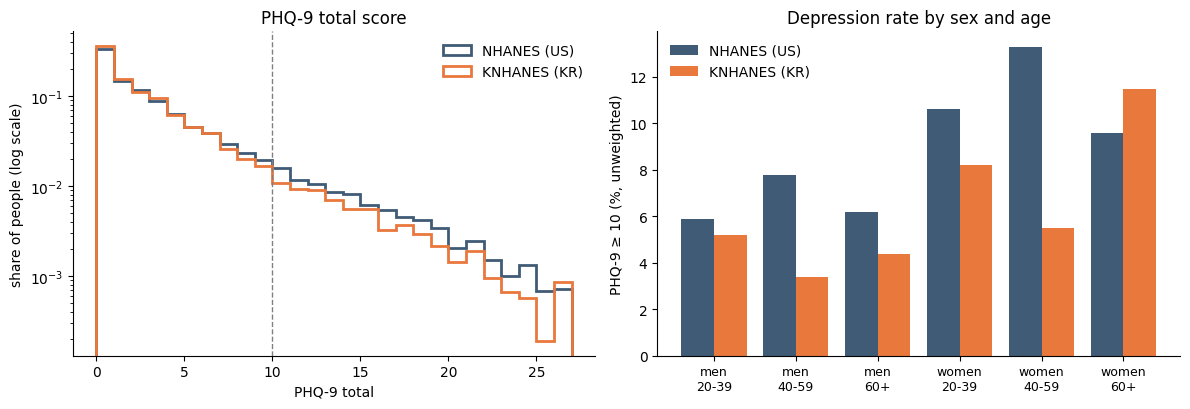

In [3]:
age_band = pd.cut(both.RIDAGEYR, [19, 39, 59, 80], labels=["20-39", "40-59", "60+"])
sex = both.RIAGENDR.map({1: "men", 2: "women"})
by_group = (both.assign(age=age_band, sex=sex)
            .groupby(["country", "sex", "age"], observed=True).depression.mean().mul(100)
            .unstack("country").round(1))
by_group = by_group[["NHANES (US)", "KNHANES (KR)"]]
display(by_group)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.arange(0, 28)
for name, color in [("NHANES (US)", US), ("KNHANES (KR)", KR)]:
    s = both.PHQ9[both.country == name]
    axes[0].hist(s, bins=bins, density=True, histtype="step", lw=2, color=color, label=name)
axes[0].axvline(10, color="grey", ls="--", lw=1)
axes[0].set_yscale("log")
axes[0].set_xlabel("PHQ-9 total")
axes[0].set_ylabel("share of people (log scale)")
axes[0].set_title("PHQ-9 total score")
axes[0].legend(frameon=False)
x = np.arange(len(by_group))
axes[1].bar(x - 0.2, by_group["NHANES (US)"], 0.4, color=US, label="NHANES (US)")
axes[1].bar(x + 0.2, by_group["KNHANES (KR)"], 0.4, color=KR, label="KNHANES (KR)")
axes[1].set_xticks(x, [f"{s}\n{a}" for s, a in by_group.index], fontsize=9)
axes[1].set_ylabel("PHQ-9 ≥ 10 (%, unweighted)")
axes[1].set_title("Depression rate by sex and age")
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "13_knhanes_outcome.png", dpi=250, bbox_inches="tight")
plt.show()

## 2. 每個特徵的分布

每個特徵都計算兩個指標：

- **國別 AUROC**：只用這一個特徵來分辨美國或韓國的 AUROC，取 max(AUC, 1 − AUC)。0.5 代表兩國分布完全一樣，1 代表完全分開。連續和類別特徵都能用，也不受單位影響。
- **SMD**：標準化平均差，(韓國平均 − 美國平均) / 合併標準差，正值代表韓國較高。只對連續特徵計算。

兩個指標都只用有作答的人：-1（問卷不適用）和缺值都排除。缺值率另外比較。

有排序的特徵直接用數值算，包括連續、二元和等級。等級特徵如教育、收入、喝酒頻率，KNHANES 的級距常比較粗，數值比較只看高低，不會因為級距粗細不同就被判成分開。沒有排序的類別特徵（婚姻、工作狀態等，見下方 `NOMINAL`）用各類別的組成來算：每一類的分數是「這一類中韓國人所占的比例」。

In [4]:
NOMINAL = ["DMDMARTL", "OCD150", "not_working_reason", "HOQ065", "WHQ030", "arthritis_type"]


def country_auc(x, is_kr, nominal):
    ok = x.notna() & (x != -1)
    x, y = x[ok], is_kr[ok]
    if y.nunique() < 2 or x.nunique() < 2:
        return np.nan
    if nominal:
        x = x.map(y.groupby(x).mean())
    a = roc_auc_score(y, x)
    return max(a, 1 - a)


is_kr = pd.Series(IS_KR, index=both.index)
rows = []
for f in FEATS:
    x = both[f]
    a, b = x[~IS_KR], x[IS_KR]
    a_ok, b_ok = a[a.notna() & (a != -1)], b[b.notna() & (b != -1)]
    cont = TYPE[f] == "continuous"
    pooled = np.sqrt((a_ok.var() + b_ok.var()) / 2)
    rows.append({"feature": f, "type": TYPE[f], "match": mapping.match[f], "years": mapping.years[f],
                 "knhanes": mapping.knhanes[f],
                 "country_auroc": country_auc(x, is_kr, f in NOMINAL),
                 "smd": (b_ok.mean() - a_ok.mean()) / pooled if cont and pooled > 0 else np.nan,
                 "us_median": a_ok.median() if cont else np.nan,
                 "kr_median": b_ok.median() if cont else np.nan,
                 "us_missing": a.isna().mean(), "kr_missing": b.isna().mean()})
shift = pd.DataFrame(rows).set_index("feature").sort_values("country_auroc", ascending=False)
shift.to_csv(OUT / "knhanes_feature_shift.csv")
print("features by country AUROC:")
display(pd.cut(shift.country_auroc, [0.5, 0.55, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
        .value_counts().sort_index().rename("features").to_frame())
print("by definition match (mean country AUROC):")
display(shift.groupby("match").country_auroc.describe()[["count", "mean", "50%"]].round(3))
display(shift.head(30).round(3))

features by country AUROC:


,features
country_auroc,
"(0.499, 0.55]",61
"(0.55, 0.6]",26
"(0.6, 0.7]",19
"(0.7, 0.8]",14
"(0.8, 1.0]",5


by definition match (mean country AUROC):


,count,mean,50%
match,,,
exact,50.0,0.569,0.543
recode,75.0,0.602,0.561


,type,match,years,knhanes,country_auroc,smd,us_median,kr_median,us_missing,kr_missing
feature,,,,,,,,,,
DR_TMOIS,continuous,recode,both,N_WATER,0.917,-1.652,2546.545,944.846,0.036,0.127
DR_TRET,continuous,recode,both,N_RETIN,0.873,-0.637,325.000,62.881,0.036,0.127
DR_TMFAT,continuous,recode,both,N_MUFA,0.828,-1.083,25.169,9.673,0.036,0.127
BMXWAIST,continuous,exact,both,HE_wc,0.819,-1.285,98.200,82.000,0.032,0.001
DR_TSFAT,continuous,recode,both,N_SFA,0.805,-0.989,22.487,9.522,0.036,0.127
DR_TTFAT,continuous,recode,both,N_FAT,0.799,-0.982,71.080,33.016,0.036,0.127
DR_TCALC,continuous,recode,both,N_CA,0.791,-0.971,812.500,430.995,0.036,0.127
WHD050,continuous,recode,both,BO1_1–BO1_3,0.787,-1.089,175.000,135.000,0.019,0.008
BMXWT,continuous,exact,both,HE_wt,0.786,-1.082,79.000,61.500,0.008,0.000


國別 AUROC 最高的 30 個特徵。顏色代表定義是否完全相同：深色是 `exact`，淺色是 `recode`。淺色特徵的差異有一部分可能來自定義不同，而不是兩國真的不同。

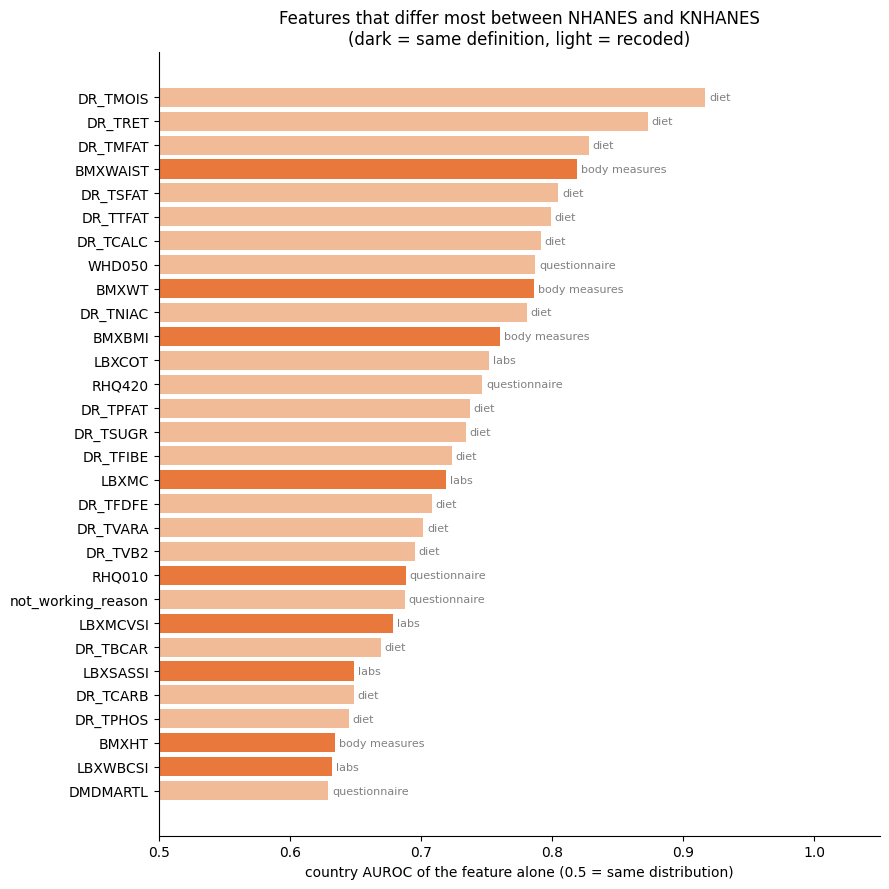

,count,mean,median,max
group,,,,
blood pressure,8,0.583,0.588,0.610
body measures,4,0.750,0.773,0.819
diet,30,0.661,0.647,0.917
labs,21,0.583,0.559,0.752
questionnaire,62,0.547,0.531,0.787


In [5]:
def group_of(f):
    if f.startswith(("LBX", "LBD", "URX")):
        return "labs"
    if f.startswith("BPX"):
        return "blood pressure"
    if f.startswith("BMX"):
        return "body measures"
    if f.startswith("DR"):
        return "diet"
    return "questionnaire"


shift["group"] = [group_of(f) for f in shift.index]
top = shift.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 9))
colors = [KR if m == "exact" else "#F2BB98" for m in top.match]
ax.barh(top.index, top.country_auroc, color=colors)
for i, (v, g) in enumerate(zip(top.country_auroc, top.group)):
    ax.text(v + 0.003, i, g, va="center", fontsize=8, color="grey")
ax.set_xlim(0.5, 1.05)
ax.set_xlabel("country AUROC of the feature alone (0.5 = same distribution)")
ax.set_title("Features that differ most between NHANES and KNHANES\n(dark = same definition, light = recoded)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "14_knhanes_shift_top.png", dpi=250, bbox_inches="tight")
plt.show()
display(shift.groupby("group").country_auroc.agg(["count", "mean", "median", "max"]).round(3))

幾個代表性的連續特徵的分布，包括身體量測、檢驗和飲食。

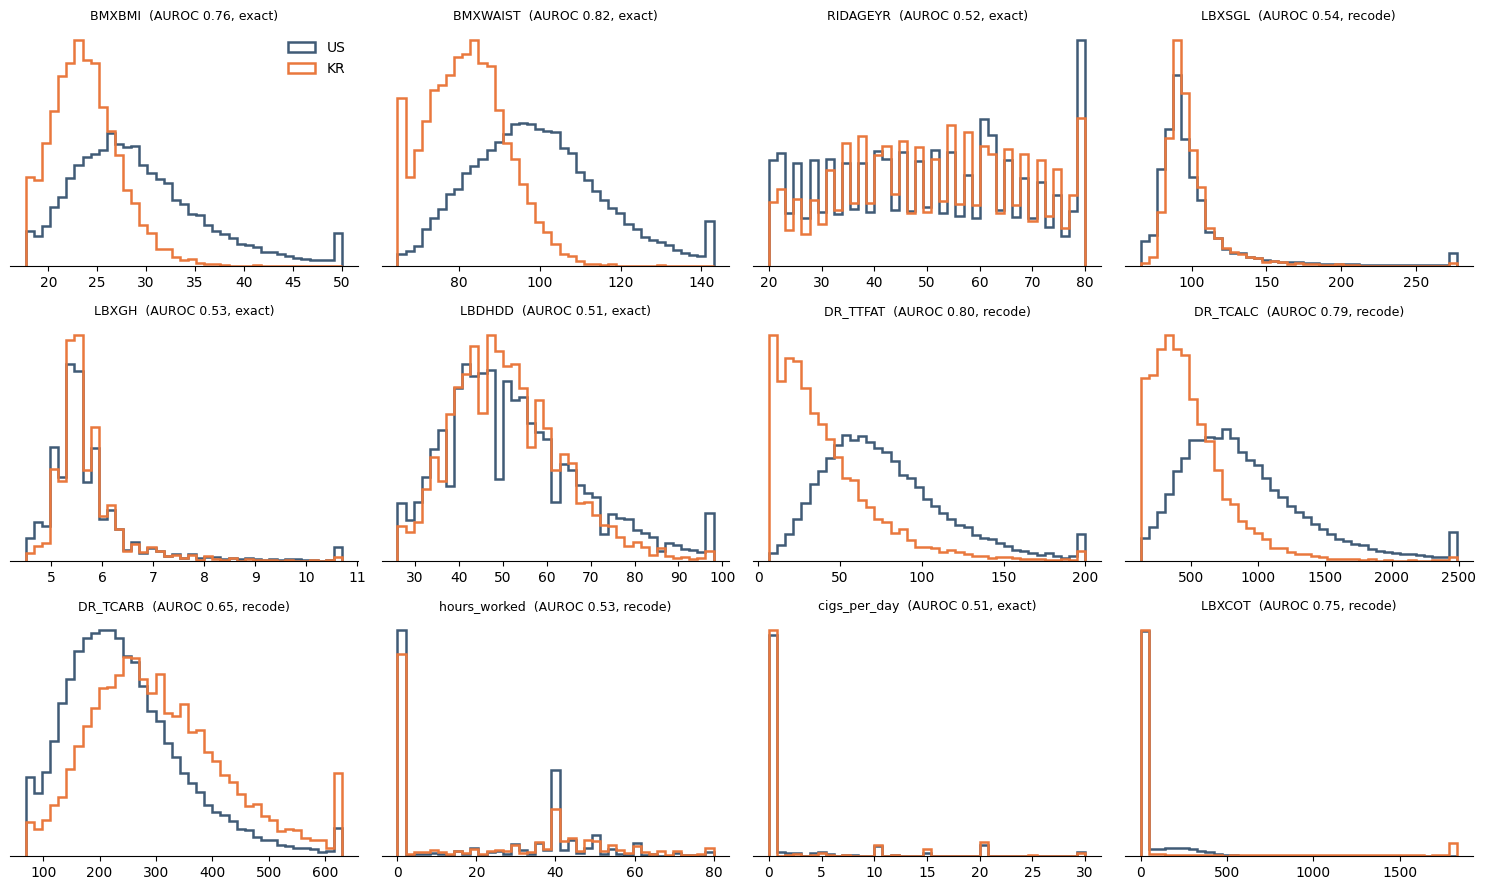

In [6]:
SHOW = ["BMXBMI", "BMXWAIST", "RIDAGEYR", "LBXSGL", "LBXGH", "LBDHDD",
        "DR_TTFAT", "DR_TCALC", "DR_TCARB", "hours_worked", "cigs_per_day", "LBXCOT"]
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for f, ax in zip(SHOW, axes.ravel()):
    a = both.loc[~IS_KR, f].replace(-1, np.nan).dropna()
    b = both.loc[IS_KR, f].replace(-1, np.nan).dropna()
    hi = np.nanpercentile(np.r_[a, b], 99)
    lo = np.nanpercentile(np.r_[a, b], 1)
    bins = np.linspace(lo, hi, 40)
    ax.hist(a.clip(lo, hi), bins=bins, density=True, histtype="step", lw=1.8, color=US, label="US")
    ax.hist(b.clip(lo, hi), bins=bins, density=True, histtype="step", lw=1.8, color=KR, label="KR")
    ax.set_title(f"{f}  (AUROC {shift.country_auroc[f]:.2f}, {shift.match[f]})", fontsize=9)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "15_knhanes_continuous.png", dpi=250, bbox_inches="tight")
plt.show()

社會和生活型態的類別特徵，比較各類別的比例。收入是用購買力平價（PPP）換算成美元年收入後，再套上 NHANES 的收入級距。

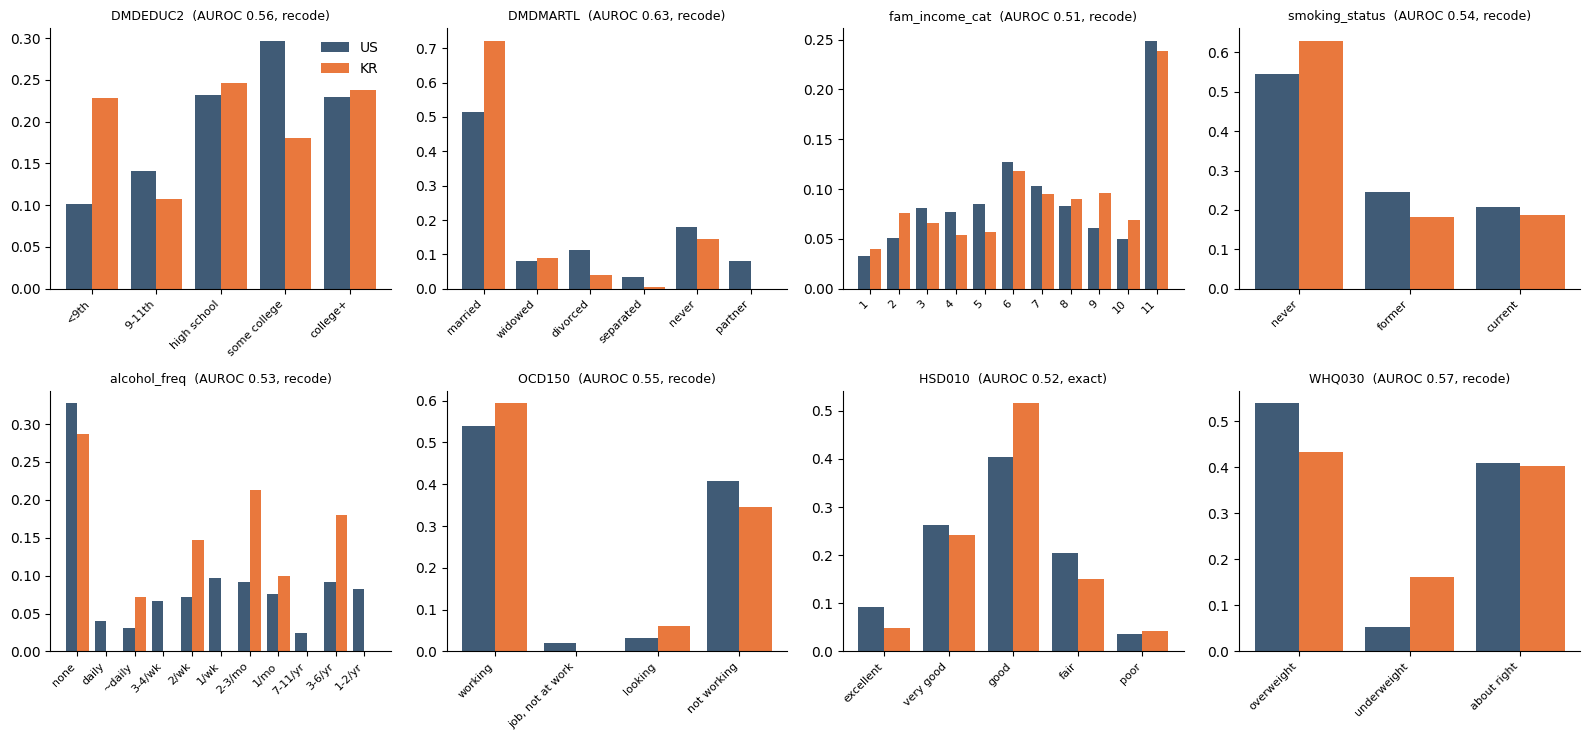

In [7]:
CATS = {"DMDEDUC2": {1: "<9th", 2: "9-11th", 3: "high school", 4: "some college", 5: "college+"},
        "DMDMARTL": {1: "married", 2: "widowed", 3: "divorced", 4: "separated", 5: "never", 6: "partner"},
        "fam_income_cat": {i: str(i) for i in range(1, 12)},
        "smoking_status": {0: "never", 1: "former", 2: "current"},
        "alcohol_freq": {0: "none", 1: "daily", 2: "~daily", 3: "3-4/wk", 4: "2/wk", 5: "1/wk",
                         6: "2-3/mo", 7: "1/mo", 8: "7-11/yr", 9: "3-6/yr", 10: "1-2/yr"},
        "OCD150": {1: "working", 2: "job, not at work", 3: "looking", 4: "not working"},
        "HSD010": {1: "excellent", 2: "very good", 3: "good", 4: "fair", 5: "poor"},
        "WHQ030": {1: "overweight", 2: "underweight", 3: "about right"}}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for (f, labels), ax in zip(CATS.items(), axes.ravel()):
    share = (both[[f, "country"]].dropna().groupby("country")[f].value_counts(normalize=True)
             .unstack(0).reindex(list(labels)).fillna(0))
    x = np.arange(len(share))
    ax.bar(x - 0.2, share["NHANES (US)"], 0.4, color=US, label="US")
    ax.bar(x + 0.2, share["KNHANES (KR)"], 0.4, color=KR, label="KR")
    ax.set_xticks(x, [labels[i] for i in share.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{f}  (AUROC {shift.country_auroc[f]:.2f}, {shift.match[f]})", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "16_knhanes_categorical.png", dpi=250, bbox_inches="tight")
plt.show()

## 3. 整體能不能分辨兩國

用 XGBoost 分辨一筆資料來自美國或韓國，報告 5 折交叉驗證的 AUROC。分別用全部特徵和各組特徵訓練，看哪一組最能分辨兩國。只用 2014、2016 兩年都有的 114 個特徵（k114）。

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict  # noqa: E402
from xgboost import XGBClassifier  # noqa: E402

K114 = list(mapping.index[mapping.years == "both"])


def country_cv(cols, seed=0):
    clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                        colsample_bytree=0.8, tree_method="hist", n_jobs=THREADS, random_state=seed)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    p = cross_val_predict(clf, both[cols], IS_KR, cv=cv, method="predict_proba")[:, 1]
    return roc_auc_score(IS_KR, p)


sets = {"all k114": K114, "k114, exact only": [f for f in K114 if mapping.match[f] == "exact"]}
for g in ["questionnaire", "body measures", "blood pressure", "labs", "diet"]:
    sets[f"{g} only"] = [f for f in K114 if group_of(f) == g]
sets["k114 without body measures and diet"] = [f for f in K114 if group_of(f) not in ("body measures", "diet")]
# measured differently in KNHANES: food moisture, urine (not serum) cotinine, COPD asked only at 40+
ARTIFACTS = ["DR_TMOIS", "LBXCOT", "MCQ160G", "MCQ160K", "DR_320Z"]
sets["k114 without 5 definition artifacts"] = [f for f in K114 if f not in ARTIFACTS]
clf_auc = pd.DataFrame([{"features": k, "n": len(v), "country AUROC (5-fold)": country_cv(v)}
                        for k, v in sets.items()]).set_index("features")
clf_auc.to_csv(OUT / "knhanes_country_classifier.csv")
display(clf_auc.round(4))

,n,country AUROC (5-fold)
features,,
all k114,114,1.0000
"k114, exact only",48,0.9925
questionnaire only,60,0.9983
body measures only,4,0.8516
blood pressure only,8,0.8887
labs only,20,0.9919
diet only,22,0.9968
k114 without body measures and diet,88,0.9998
k114 without 5 definition artifacts,109,0.9998


In [9]:
clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                    colsample_bytree=0.8, tree_method="hist", n_jobs=THREADS, random_state=0,
                    importance_type="total_gain")
clf.fit(both[K114], IS_KR)
imp = pd.Series(clf.feature_importances_, index=K114).sort_values(ascending=False)
display((imp / imp.sum()).head(15).round(3).rename("share of total gain").to_frame()
        .join(shift[["match", "country_auroc"]]))

,share of total gain,match,country_auroc
DR_TMOIS,0.382,recode,0.916563
LBXCOT,0.172,recode,0.751707
MCQ160G,0.077,recode,0.505285
DR_320Z,0.064,recode,0.533031
DR_TRET,0.056,recode,0.872715
BMXWAIST,0.055,exact,0.819032
DR_TPOTA,0.033,recode,0.572174
MCQ160K,0.021,recode,0.524855
DR_TMFAT,0.019,recode,0.827904
DR_TCARB,0.017,recode,0.648776


## 4. 特徵和憂鬱的關係，在兩國是否一致

這是外部測試最關鍵的一項。每個特徵在兩國各自計算單變量 AUROC：把特徵值當成預測 PHQ-9 ≥ 10 的分數。

- 數值越大越可能憂鬱，AUROC > 0.5；越小越可能憂鬱，AUROC < 0.5；0.5 代表沒有關聯。
- 有排序的特徵直接用數值，包括連續、二元和等級。
- 沒有排序的類別特徵（婚姻、工作狀態、不工作的原因、住宅、體型自覺、關節炎類型）不適合用數值算 AUROC，另外比較各類別的憂鬱率。

兩國差異的標準誤用 Hanley–McNeil 公式估計，z = 差 / √(SE₁² + SE₂²)。

單變量 AUROC 會受族群組成影響。KNHANES 女性較多，韓國的憂鬱又集中在 60 歲以上女性，所以和年齡、性別有關的特徵可能只是反映組成不同。因此另外計算**分層 AUROC**：在性別 × 三個年齡組的 6 層內分別計算 AUROC，再依各層的病例數加權平均。比較的重點放在分層後的結果。

In [10]:
def auc_se(a, n1, n0):
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0))


def dep_auc(g, f):
    ok = g[f].notna() & (g[f] != -1)
    y, x = g.depression[ok], g[f][ok]
    if y.nunique() < 2 or x.nunique() < 2:
        return np.nan, np.nan, int(ok.sum())
    a = roc_auc_score(y, x)
    return a, auc_se(a, int(y.sum()), int((1 - y).sum())), int(ok.sum())


def strat_auc(g, f):
    """Case-weighted mean of the AUROC within sex x age strata."""
    aucs, cases = [], []
    for _, s in g.groupby(["sex", "age"], observed=True):
        a, _, _ = dep_auc(s, f)
        if a == a:
            aucs.append(a)
            cases.append(s.depression.sum())
    return np.average(aucs, weights=cases) if aucs else np.nan


strata = both.assign(age=age_band, sex=sex)
rel = []
for f in FEATS:
    if f in NOMINAL:
        continue
    r = {"feature": f, "match": mapping.match[f]}
    for name, g in strata.groupby("country"):
        tag = "us" if name.startswith("NHANES") else "kr"
        r[f"auc_{tag}"], r[f"se_{tag}"], r[f"n_{tag}"] = dep_auc(g, f)
        r[f"strat_{tag}"] = strat_auc(g, f) if f not in ("RIDAGEYR", "RIAGENDR") else np.nan
    rel.append(r)
rel = pd.DataFrame(rel).set_index("feature")
rel["diff"] = rel.auc_kr - rel.auc_us
rel["z"] = rel["diff"] / np.sqrt(rel.se_us ** 2 + rel.se_kr ** 2)
rel["strat_diff"] = rel.strat_kr - rel.strat_us
rel.to_csv(OUT / "knhanes_feature_relation.csv")
summary = []
for kind, us, kr in [("crude", "auc_us", "auc_kr"), ("sex x age stratified", "strat_us", "strat_kr")]:
    r = rel.dropna(subset=[us, kr])
    strong = (r[us] - 0.5).abs() >= 0.05
    same = np.sign(r[us] - 0.5) == np.sign(r[kr] - 0.5)
    summary.append({"AUROC": kind, "features": len(r),
                    "Spearman (US vs KR)": r[[us, kr]].corr("spearman").iloc[0, 1],
                    "|AUROC-0.5| >= 0.05 in US": int(strong.sum()),
                    "of those, same direction in KR": int((strong & same).sum()),
                    "opposite direction, both |AUROC-0.5| >= 0.03":
                        int((~same & ((r[us] - 0.5).abs() >= 0.03) & ((r[kr] - 0.5).abs() >= 0.03)).sum())})
display(pd.DataFrame(summary).set_index("AUROC").round(2))
print(f"crude difference with |z| > 3: {int((rel.z.abs() > 3).sum())} features")
display(rel.reindex(rel["strat_diff"].abs().sort_values(ascending=False).index)
        [["match", "auc_us", "auc_kr", "z", "strat_us", "strat_kr", "strat_diff", "n_kr"]].head(20).round(3))

,features,Spearman (US vs KR),|AUROC-0.5| >= 0.05 in US,"of those, same direction in KR","opposite direction, both |AUROC-0.5| >= 0.03"
AUROC,,,,,
crude,119,0.76,42,40,3
sex x age stratified,117,0.75,37,34,1


crude difference with |z| > 3: 39 features


,match,auc_us,auc_kr,z,strat_us,strat_kr,strat_diff,n_kr
feature,,,,,,,,
DR_TSUGR,recode,0.515,0.383,-7.952,0.528,0.404,-0.123,4829
RHQ010,exact,0.456,0.559,6.714,0.456,0.538,0.083,5991
BMXBMI,exact,0.569,0.483,-6.815,0.563,0.485,-0.078,10510
BMXWT,exact,0.535,0.429,-8.766,0.556,0.479,-0.077,10513
DR_TMOIS,recode,0.479,0.385,-7.640,0.488,0.411,-0.077,9185
WHD050,recode,0.533,0.433,-8.220,0.559,0.483,-0.075,10434
BMXWAIST,exact,0.564,0.489,-5.892,0.576,0.502,-0.074,10505
hours_worked,recode,0.372,0.393,1.881,0.368,0.439,0.071,10503
DMDHHSIZ,exact,0.487,0.398,-7.505,0.478,0.412,-0.066,10518


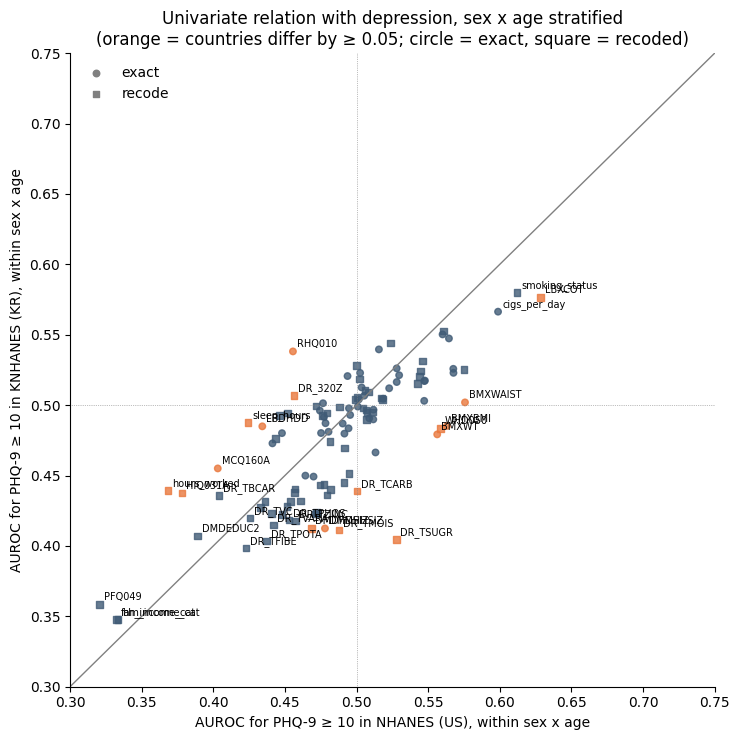

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
lim = (0.3, 0.75)
ax.plot(lim, lim, color="grey", lw=1)
ax.axhline(0.5, color="grey", lw=0.5, ls=":")
ax.axvline(0.5, color="grey", lw=0.5, ls=":")
sr = rel.dropna(subset=["strat_us", "strat_kr"])
big = sr.strat_diff.abs() >= 0.05
for m, marker in [("exact", "o"), ("recode", "s")]:
    s = sr[sr.match == m]
    ax.scatter(s.strat_us, s.strat_kr, s=22, marker=marker, alpha=0.8,
               color=[KR if b else US for b in big[s.index]])
    ax.scatter([], [], s=22, marker=marker, color="grey", label=m)
label = sr[big | ((sr.strat_us - 0.5).abs() > 0.08) | ((sr.strat_kr - 0.5).abs() > 0.08)]
for f, r in label.iterrows():
    ax.annotate(f, (r.strat_us, r.strat_kr), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("AUROC for PHQ-9 ≥ 10 in NHANES (US), within sex x age")
ax.set_ylabel("AUROC for PHQ-9 ≥ 10 in KNHANES (KR), within sex x age")
ax.set_title("Univariate relation with depression, sex x age stratified\n"
             "(orange = countries differ by ≥ 0.05; circle = exact, square = recoded)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "17_knhanes_relation.png", dpi=250, bbox_inches="tight")
plt.show()

沒有排序的類別特徵：比較各類別的憂鬱率（%），括號內是人數。

,NHANES (US),KNHANES (KR)
DMDMARTL: married,"6.1 (17,178)","4.8 (7,587)"
DMDMARTL: widowed,"10.8 (2,694)",12.2 (936)
DMDMARTL: divorced,"14.2 (3,737)",18.6 (415)
DMDMARTL: separated,"18.1 (1,140)",17.0 (53)
DMDMARTL: never,"10.2 (6,036)","8.3 (1,523)"
DMDMARTL: partner,"10.4 (2,694)",
OCD150: working,"5.3 (18,056)","4.3 (6,235)"
"OCD150: job, not at work",5.4 (698),
OCD150: looking,"11.3 (1,053)",6.9 (635)
OCD150: not working,"13.6 (13,673)","10.4 (3,638)"


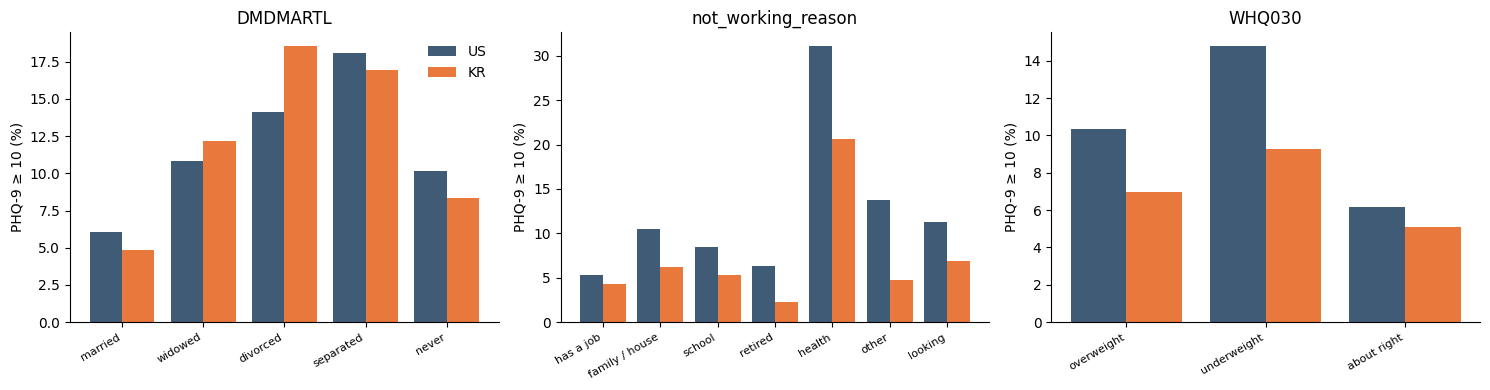

In [12]:
NOMINAL_LABELS = {
    "DMDMARTL": CATS["DMDMARTL"], "OCD150": CATS["OCD150"], "WHQ030": CATS["WHQ030"],
    "not_working_reason": {0: "has a job", 1: "family / house", 2: "school", 3: "retired",
                           4: "health", 5: "layoff", 6: "disabled", 7: "other", 10: "looking"},
    "HOQ065": {1: "owned", 2: "rented", 3: "other"},
    "arthritis_type": {0: "none", 1: "osteo", 2: "rheumatoid", 3: "other"}}
tabs = []
for f, labels in NOMINAL_LABELS.items():
    t = (both.dropna(subset=[f]).groupby([f, "country"]).depression.agg(["mean", "size"])
         .unstack("country"))
    t.index = [f"{f}: {labels.get(int(i), i)}" for i in t.index]
    tabs.append(t)
nom = pd.concat(tabs)
fmt = pd.DataFrame({c: [f"{100 * m:.1f} ({int(n):,})" if n == n else "" for m, n in
                        zip(nom[("mean", c)], nom[("size", c)])] for c in ["NHANES (US)", "KNHANES (KR)"]},
                   index=nom.index)
display(fmt)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for f, ax in zip(["DMDMARTL", "not_working_reason", "WHQ030"], axes):
    t = nom.loc[[i for i in nom.index if i.startswith(f + ":")]]
    t = t[(t[("size", "NHANES (US)")] >= 30) & (t[("size", "KNHANES (KR)")] >= 30)]
    x = np.arange(len(t))
    ax.bar(x - 0.2, 100 * t[("mean", "NHANES (US)")], 0.4, color=US, label="US")
    ax.bar(x + 0.2, 100 * t[("mean", "KNHANES (KR)")], 0.4, color=KR, label="KR")
    ax.set_xticks(x, [i.split(": ")[1] for i in t.index], rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("PHQ-9 ≥ 10 (%)")
    ax.set_title(f)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "18_knhanes_nominal.png", dpi=250, bbox_inches="tight")
plt.show()

## 結論

1. **結果變數**：KNHANES 的 PHQ-9 ≥ 10 是 6.6%（加權 6.2%），NHANES 是 8.9%（加權 7.7%）。差異主要在 40–59 歲：韓國男性 3.4%、女性 5.5%，美國分別是 7.8% 和 13.3%。韓國 60 歲以上女性反而較高（11.5% 對 9.6%）。也就是說，憂鬱集中在哪些人身上，兩國不同。
2. **特徵分布**：差最多的是體型和飲食。韓國的腰圍、體重、BMI 低約 1 個標準差，脂肪、鈣、菸鹼酸攝取低約 1 個標準差，碳水化合物和纖維較高。教育程度的組成也不同：韓國的高齡者多數只讀到國小，60 歲以上很多人小於 9 年級。其他問卷特徵（疾病史、抽菸狀態、工作、收入級距）的國別 AUROC 大多低於 0.6。不過有幾項較大的差異其實來自定義不同，不是兩國真的不同：
   - 飲食的水分（`DR_TMOIS`）：兩國食物成分表計算水分的方式不同。
   - cotinine（`LBXCOT`）：NHANES 是血清，KNHANES 是尿液，兩者數值不能直接比。
   - COPD（`MCQ160G` / `MCQ160K`）：KNHANES 只問 40 歲以上，造成缺值型態不同。
3. **整體可分辨度**：用全部特徵分辨兩國的 AUROC 幾乎是 1，只用定義相同的 48 個特徵也有 0.99。所以兩國資料幾乎不重疊，外部測試一定落在模型沒看過的區域。這本身是預期中的：外部驗證就是要看這種情況下模型還能不能用。
4. **特徵和憂鬱的關係大多一致**。按性別 × 年齡分層後，兩國單變量 AUROC 的 Spearman 相關是 0.75。在美國有關聯（|AUROC − 0.5| ≥ 0.05）的 37 個特徵中，34 個在韓國方向相同。最強的訊號在兩國都一樣強：自評健康、活動受限、收入、教育、抽菸。明顯不同的有三類：
   - **體型**（BMI、體重、腰圍、一年前體重）：美國體重越高越可能憂鬱，韓國沒有關聯或略反。這和文獻中亞洲族群肥胖與憂鬱關聯較弱的結果一致。
   - **初經年齡**（`RHQ010`）：美國初經較早的人較可能憂鬱，韓國相反，分層後仍然如此。
   - **飲食量、家戶人數、睡眠**：韓國吃得少、家戶人數少的人較可能憂鬱，關聯比美國強。睡眠在美國有關聯，在韓國較弱。注意 KNHANES 的睡眠只有 2016 年，而且問的是平日平均。

**對外部測試的意義**：主要的預測訊號（自評健康、活動受限、社經地位、抽菸）在兩國一致，所以模型有機會轉移。體型和飲食相關的特徵在兩國關係不同，分布又差很多，是最可能讓外部表現下降的來源。外部測試時可以比較兩種模型：一個用全部 k114，另一個拿掉這些特徵和定義不同的特徵，看下降的幅度是否變小。